# Tugas Praktikum HDBSCAN — Iris Dataset

Tujuan: memuat data Iris, menerapkan HDBSCAN, melaporkan jumlah cluster/noise, memvisualisasikan menggunakan PCA, dan membandingkan dengan label asli.

Implementasi menggunakan `sklearn.cluster.HDBSCAN` (scikit-learn versi 1.3 atau lebih baru).

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

In [5]:
# 1. Load dataset Iris
iris = load_iris()
X = iris.data
y_true = iris.target

print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Nama spesies:", list(iris.target_names))

df_iris = pd.DataFrame(X, columns=iris.feature_names)
print(df_iris.head().to_string(index=False))

Jumlah data: 150
Jumlah fitur: 4
Nama spesies: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
               5.1               3.5                1.4               0.2
               4.9               3.0                1.4               0.2
               4.7               3.2                1.3               0.2
               4.6               3.1                1.5               0.2
               5.0               3.6                1.4               0.2


In [6]:
# 2. Standarisasi sebelum clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. HDBSCAN: tidak menggunakan label asli untuk membuat cluster
model = HDBSCAN(
    min_cluster_size=15,
    min_samples=6,
    cluster_selection_method="eom",
    copy=True
)
labels = model.fit_predict(X_scaled)

n_clusters = len(set(labels) - {-1})
n_noise = int(np.sum(labels == -1))

print("Jumlah cluster:", n_clusters)
print("Jumlah noise:", n_noise)
print("Distribusi hasil:")
print(pd.Series(labels, name="Cluster").value_counts().sort_index())

Jumlah cluster: 2
Jumlah noise: 2
Distribusi hasil:
Cluster
-1     2
 0    50
 1    98
Name: count, dtype: int64


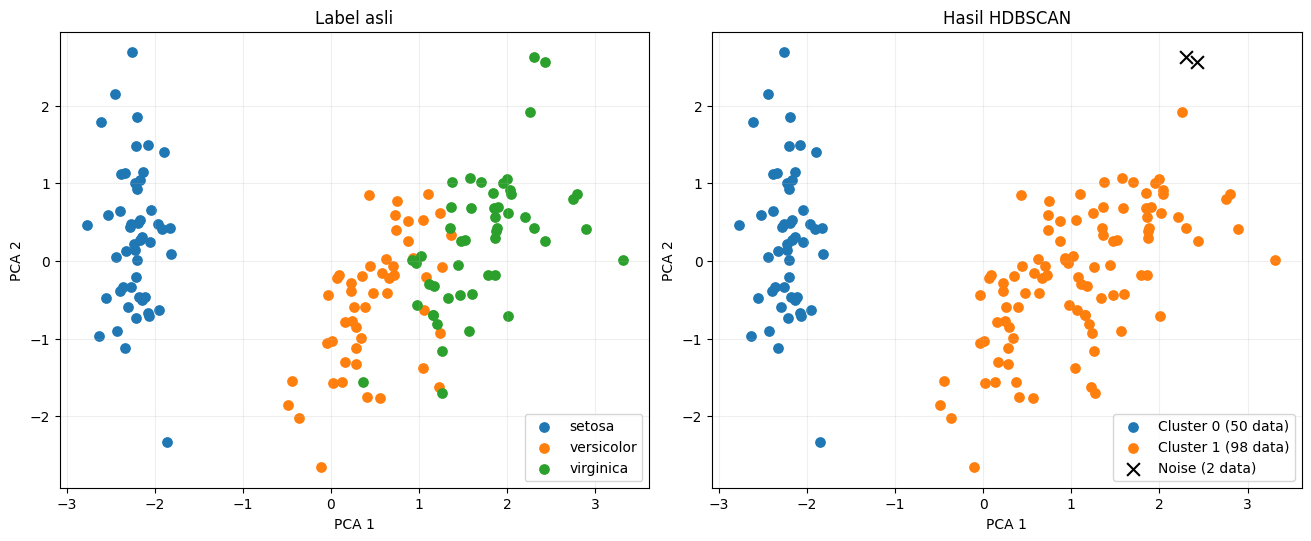

In [7]:
# 4. Visualisasi PCA (hanya untuk visualisasi; model menggunakan 4 fitur)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.3), constrained_layout=True)
for kelas, nama in enumerate(iris.target_names):
    mask = y_true == kelas
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=45, label=nama)

for cluster in sorted(set(labels) - {-1}):
    mask = labels == cluster
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], s=45,
                    label=f"Cluster {cluster} ({mask.sum()} data)")

if (labels == -1).any():
    mask = labels == -1
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], c="black",
                    marker="x", s=85, label=f"Noise ({mask.sum()} data)")

for ax, title in zip(axes, ["Label asli", "Hasil HDBSCAN"]):
    ax.set_title(title)
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.legend()
    ax.grid(alpha=0.2)

plt.show()

In [8]:
# 5. Perbandingan dengan label asli dan evaluasi
crosstab = pd.crosstab(
    pd.Series(y_true).map(dict(enumerate(iris.target_names))),
    pd.Series(labels, name="Hasil HDBSCAN"),
    rownames=["Spesies asli"]
)
print("Tabel perbandingan label asli vs hasil HDBSCAN:")
print(crosstab.to_string())

ari = adjusted_rand_score(y_true, labels)
mask = labels != -1
sil = silhouette_score(X_scaled[mask], labels[mask]) if len(set(labels[mask])) >= 2 else float("nan")
print(f"\nAdjusted Rand Index (ARI): {ari:.4f}")
print(f"Silhouette (tanpa noise): {sil:.4f}")
print("Kesimpulan: setosa terpisah; versicolor dan virginica tergabung.")

Tabel perbandingan label asli vs hasil HDBSCAN:
Hasil HDBSCAN  -1   0   1
Spesies asli             
setosa          0  50   0
versicolor      0   0  50
virginica       2   0  48

Adjusted Rand Index (ARI): 0.5638
Silhouette (tanpa noise): 0.5899
Kesimpulan: setosa terpisah; versicolor dan virginica tergabung.


**Interpretasi:** HDBSCAN mengidentifikasi dua kelompok padat, bukan ketiga spesies asli. Iris-setosa terkelompok sempurna pada cluster tersendiri; Iris-versicolor dan sebagian besar Iris-virginica berada pada cluster yang sama. Ini wajar karena clustering merupakan *unsupervised learning*, sehingga label asli tidak digunakan saat pembentukan cluster.

**Catatan:** Notebook menggunakan HDBSCAN bawaan scikit-learn. Pustaka pihak ketiga `hdbscan` pada modul praktikum memiliki perbedaan teknis parameter `min_samples`.